# Figure 2: CosMx expression-space UMAPs — Lung5_Rep1

Dataset-specific copy of `Figure2_UMAPs.ipynb`. The default panels are reference, Raw, ResolVI and Syndri (last). Edit `PLOT_PANELS` to select methods; SPLIT is available and ovrlpy is available only for CosMx. Preprocessing, UMAP parameters and the original notebook's threshold-based Syndri cleaning are preserved. Syndri target fraction: **0.5**, minimum removal probability: **0.5**.

The reference uses `.X` counts and labels compatible with this dataset. Cell-type colors are shared across panels and generated from the observed labels. Figures have dataset/slice-specific names and existing exports are protected from overwriting.


In [1]:
from pathlib import Path
import warnings

import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_hex
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import seaborn as sns

sc.settings.verbosity = 2
sns.set_theme(style="white", context="paper")

# nsclc_cosmx: section Lung5_Rep1.
DATASET = 'nsclc_cosmx'
SLICE_TAG = 'Lung5_Rep1'
REFERENCE_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/interim/single-cell/sc_integrated.h5ad')
SPATIAL_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/final/st_integrated_slice-Lung5_Rep1.h5ad')
RESOLVI_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/competitors/resolvi/st_integrated_slice-Lung5_Rep1.h5ad')
OVRLPY_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/competitors/ovrlpy_pixel_correction/st_integrated_slice-Lung5_Rep1.h5ad')
OUTPUT_DIR = Path('/home/jwinchel/Syndri/figures/outputs')
QC_CELL_SELECTION = 'intersection'  # 'intersection' or 'per_method'
# Select and order panels here. For example: ['Raw spatial', 'ResolVI-corrected', 'Syndri-cleaned'].
PLOT_PANELS = [
    'scRNA-seq reference',
    'Raw spatial',
    'SPLIT-purified',
    'ResolVI-corrected',
    'ovrlpy 0.7-corrected',
    'CellAdmix',  # Placeholder until its corrected matrix is available.
    'Syndri-cleaned',
]
PANEL_TAGS = {
    'scRNA-seq reference': 'reference',
    'Raw spatial': 'raw',
    'SPLIT-purified': 'split',
    'ResolVI-corrected': 'resolvi',
    'ovrlpy 0.7-corrected': 'ovrlpy',
    'CellAdmix': 'celladmix',
    'Syndri-cleaned': 'syndri',
}
if not PLOT_PANELS or len(PLOT_PANELS) != len(set(PLOT_PANELS)):
    raise ValueError('PLOT_PANELS must contain unique panel names and cannot be empty')
unknown_panels = set(PLOT_PANELS) - set(PANEL_TAGS)
if unknown_panels:
    raise ValueError(f'Unknown PLOT_PANELS: {sorted(unknown_panels)}')
if PLOT_PANELS == ['CellAdmix']:
    raise ValueError('CellAdmix is currently a placeholder; select another panel too')
panel_tag = '_'.join(PANEL_TAGS[panel] for panel in PLOT_PANELS)
OUTPUT_STEM = OUTPUT_DIR / (
    f'Figure2_UMAPs_{DATASET}_{SLICE_TAG}_qc10counts5genes_target0.5_minP05_'
    f'{QC_CELL_SELECTION}QC_{panel_tag}'
)

REFERENCE_LAYER = None  # Use reference.X counts.
REFERENCE_LABEL = 'cell_type_harmonized'
SPATIAL_LABEL = 'cell_type_harmonized'
PROBABILITY_LAYER = 'syndri_admix_probs_X'
SPLIT_LAYER = 'split_purified_counts_X'
RESOLVI_LAYER = 'resolvi_corrected_counts'
OVRLPY_LAYER = 'ovrlpy_corrected_counts_vsi_lt_0_7'
TARGET_REMOVED_FRACTION = 0.7
MIN_SYNDRI_REMOVAL_PROBABILITY = 0.5
MIN_COUNTS = 10
MIN_GENES = 5
MAX_SPATIAL_CELLS = None  # Use every cell from this one spatial slice.
N_PCS = 50
N_NEIGHBORS = 15
MIN_DIST = 0.4
RANDOM_STATE = 42
POINT_SIZE = 2.0
if QC_CELL_SELECTION not in {'intersection', 'per_method'}:
    raise ValueError("QC_CELL_SELECTION must be 'intersection' or 'per_method'")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for output_path in (OUTPUT_STEM.with_suffix('.pdf'), OUTPUT_STEM.with_suffix('.png')):
    if output_path.exists():
        raise FileExistsError(f'Refusing to overwrite existing UMAP figure: {output_path}')

FileExistsError: Refusing to overwrite existing UMAP figure: /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_nsclc_cosmx_Lung5_Rep1_qc10counts5genes_target0.pdf

## Load and validate inputs

Use the dataset's matched single-cell reference and spatial slice. Corrected matrices are aligned to the spatial cell and gene IDs before subsetting to the shared measured gene panel. Aging-brain inputs use milestone 87 on regenerated RCTD inputs. ResolVI uses the current corrected-count export; normalization and log1p are applied below.


In [ ]:
input_paths = [REFERENCE_PATH, SPATIAL_PATH]
if 'ResolVI-corrected' in PLOT_PANELS:
    input_paths.append(RESOLVI_PATH)
if 'ovrlpy 0.7-corrected' in PLOT_PANELS:
    if OVRLPY_PATH is None:
        raise ValueError('ovrlpy corrected counts are unavailable for this dataset')
    input_paths.append(OVRLPY_PATH)
for path in input_paths:
    if not path.exists():
        raise FileNotFoundError(path)

reference = ad.read_h5ad(REFERENCE_PATH)
spatial = ad.read_h5ad(SPATIAL_PATH)
resolvi = ad.read_h5ad(RESOLVI_PATH) if 'ResolVI-corrected' in PLOT_PANELS else None
ovrlpy = ad.read_h5ad(OVRLPY_PATH) if 'ovrlpy 0.7-corrected' in PLOT_PANELS else None
competitors = {'ResolVI': resolvi, 'ovrlpy': ovrlpy}
for method, competitor in competitors.items():
    if competitor is not None and (
        not spatial.obs_names.equals(competitor.obs_names)
        or not spatial.var_names.equals(competitor.var_names)
    ):
        raise ValueError(f'{method} cells and genes do not match the final spatial AnnData')

required = {'spatial label': (SPATIAL_LABEL, spatial.obs)}
if 'scRNA-seq reference' in PLOT_PANELS:
    if REFERENCE_LAYER is not None:
        required['reference layer'] = (REFERENCE_LAYER, reference.layers)
    required['reference label'] = (REFERENCE_LABEL, reference.obs)
if 'Syndri-cleaned' in PLOT_PANELS:
    required['Syndri probabilities'] = (PROBABILITY_LAYER, spatial.layers)
if 'SPLIT-purified' in PLOT_PANELS:
    required['SPLIT counts'] = (SPLIT_LAYER, spatial.layers)
if resolvi is not None:
    required['ResolVI counts'] = (RESOLVI_LAYER, resolvi.layers)
if ovrlpy is not None:
    required['ovrlpy 0.7 counts'] = (OVRLPY_LAYER, ovrlpy.layers)
missing = [description for description, (key, container) in required.items() if key not in container]
if missing:
    raise KeyError(f'Missing required inputs: {missing}')

def feature_names(adata):
    ids = pd.Series(adata.var_names.astype(str), index=adata.var_names, dtype='string')
    key = next((k for k in ['feature_name', 'gene_symbol', 'name'] if k in adata.var), None)
    names = adata.var[key].astype('string').str.strip() if key else ids.copy()
    missing = names.isna() | names.str.lower().isin(['', 'n/a', 'na', 'nan', 'none'])
    return pd.Index(names.mask(missing, ids).astype(str))

reference.var_names = feature_names(reference)
spatial.var_names = feature_names(spatial)
for competitor in competitors.values():
    if competitor is not None:
        competitor.var_names = feature_names(competitor)
for adata in (reference, spatial, *[c for c in competitors.values() if c is not None]):
    adata.var_names_make_unique()
for method, competitor in competitors.items():
    if competitor is not None and not spatial.var_names.equals(competitor.var_names):
        raise ValueError(f'{method} feature names do not match the final spatial AnnData')
common_genes = spatial.var_names[spatial.var_names.isin(reference.var_names)]
if len(common_genes) < 3:
    raise ValueError(f'Only {len(common_genes)} shared genes were found')
reference = reference[:, common_genes].copy()
spatial = spatial[:, common_genes].copy()
for method, competitor in competitors.items():
    if competitor is not None:
        competitors[method] = competitor[:, common_genes].copy()

valid = spatial.obs[SPATIAL_LABEL].notna() & spatial.obs[SPATIAL_LABEL].astype(str).ne('nan')
spatial = spatial[valid].copy()
for method, competitor in competitors.items():
    if competitor is not None:
        competitors[method] = competitor[valid].copy()
if MAX_SPATIAL_CELLS is not None and spatial.n_obs > MAX_SPATIAL_CELLS:
    rng = np.random.default_rng(RANDOM_STATE)
    keep = np.sort(rng.choice(spatial.n_obs, MAX_SPATIAL_CELLS, replace=False))
    spatial = spatial[keep].copy()
    for method, competitor in competitors.items():
        if competitor is not None:
            competitors[method] = competitor[keep].copy()
resolvi, ovrlpy = competitors['ResolVI'], competitors['ovrlpy']

print(f'Reference: {reference.n_obs:,} cells x {reference.n_vars:,} shared genes')
print(f'Spatial:   {spatial.n_obs:,} cells x {spatial.n_vars:,} shared genes')
print(f'Spatial sample: {SPATIAL_PATH.name}')


Reference: 40,362 cells x 956 shared genes
Spatial:   98,002 cells x 956 shared genes
Spatial sample: st_integrated_slice-Lung5_Rep1.h5ad


## Construct the Syndri-cleaned matrix

Within each annotated cell type, the probability cutoff targets the requested fraction of transcript count mass, but never falls below `MIN_SYNDRI_REMOVAL_PROBABILITY`. Transcripts with smaller admixture probabilities are always retained. If too few transcripts meet the probability floor, the achieved removal fraction will be below the target.


In [ ]:
def as_csr(matrix):
    return matrix.tocsr().astype(np.float32) if sp.issparse(matrix) else sp.csr_matrix(np.asarray(matrix, dtype=np.float32))

def clean_by_cell_type(counts, probabilities, labels, target_fraction, min_probability):
    counts = as_csr(counts)
    probabilities = as_csr(probabilities)
    if counts.shape != probabilities.shape:
        raise ValueError('Counts and Syndri probabilities must have identical shapes')
    if not 0 <= target_fraction <= 1:
        raise ValueError('TARGET_REMOVED_FRACTION must be between 0 and 1')
    if not np.isfinite(min_probability) or not 0 <= min_probability <= 1:
        raise ValueError('MIN_SYNDRI_REMOVAL_PROBABILITY must be between 0 and 1')

    cleaned = counts.copy()
    labels = np.asarray(labels).astype(str)
    records = []
    for label in pd.unique(labels):
        rows = np.flatnonzero(labels == label)
        block = counts[rows].tocoo()
        total = float(block.data.sum())
        if block.nnz == 0 or total == 0:
            records.append((label, np.inf, 0.0))
            continue
        p = np.asarray(probabilities[rows][block.row, block.col]).ravel()
        eligible = p >= min_probability
        if target_fraction == 0 or not np.any(eligible):
            records.append((label, np.inf, 0.0))
            continue
        eligible_probabilities = p[eligible]
        eligible_counts = block.data[eligible]
        order = np.argsort(eligible_probabilities)[::-1]
        cumulative = np.cumsum(eligible_counts[order], dtype=np.float64)
        stop = min(np.searchsorted(cumulative, target_fraction * total, side='left'), len(order) - 1)
        threshold = float(eligible_probabilities[order[stop]])
        remove = eligible & (p >= threshold)
        records.append((label, threshold, float(block.data[remove].sum() / total)))

        block_clean = cleaned[rows].tolil()
        for local_row, col in zip(block.row[remove], block.col[remove]):
            block_clean[local_row, col] = 0
        cleaned[rows] = block_clean.tocsr()

    cleaned.eliminate_zeros()
    thresholds = pd.DataFrame(records, columns=['cell_type', 'admix_prob_threshold', 'achieved_removed_fraction'])
    return cleaned, thresholds

raw_counts = as_csr(spatial.X)
spatial_matrices = {}
for panel in PLOT_PANELS:
    if panel == 'Raw spatial':
        spatial_matrices[panel] = raw_counts
    elif panel == 'SPLIT-purified':
        spatial_matrices[panel] = as_csr(spatial.layers[SPLIT_LAYER])
    elif panel == 'ResolVI-corrected':
        spatial_matrices[panel] = as_csr(resolvi.layers[RESOLVI_LAYER])
    elif panel == 'ovrlpy 0.7-corrected':
        spatial_matrices[panel] = as_csr(ovrlpy.layers[OVRLPY_LAYER])
    elif panel == 'Syndri-cleaned':
        syndri_counts, syndri_thresholds = clean_by_cell_type(
            raw_counts, spatial.layers[PROBABILITY_LAYER], spatial.obs[SPATIAL_LABEL],
            TARGET_REMOVED_FRACTION, MIN_SYNDRI_REMOVAL_PROBABILITY,
        )
        spatial_matrices[panel] = syndri_counts
        display(syndri_thresholds.sort_values('cell_type').reset_index(drop=True))
for panel, counts in spatial_matrices.items():
    if counts.shape != raw_counts.shape:
        raise ValueError(f'{panel} counts do not match the selected spatial cells and genes')


,cell_type,admix_prob_threshold,achieved_removed_fraction
0,B cells,0.948770,0.500000
1,DC,0.890300,0.500000
2,Endothelial,0.907672,0.500000
3,Epithelial,0.824807,0.500000
4,Fibroblast,0.770667,0.500000
5,Macrophage,0.827986,0.500004
6,Malignant,0.724206,0.500000
7,Mast,0.927452,0.500001
8,Monocyte,0.891642,0.500005
9,NK,0.914664,0.500000


## Compute independent UMAPs

Before normalization, retain cells with at least 10 counts and 5 detected genes in each count matrix. The reference is filtered on its own counts. With `QC_CELL_SELECTION = 'intersection'`, all selected spatial panels use the same cells passing QC in each selected method's counts. With `'per_method'`, each spatial panel uses its own QC-passing cells; the printed counts show the difference. All matrices then use the metric pipeline's per-cell normalization to 10,000, log transform, and 50-PC representation before the neighbor graph and UMAP. Gene-wise scaling is omitted, as in the separation metrics.


In [ ]:
def compute_umap(template, matrix, label_key, title):
    current = ad.AnnData(
        X=as_csr(matrix),
        # Retain every observation-level annotation for downstream coloring.
        obs=template.obs.copy(),
        var=template.var.copy(),
    )
    current.obs['cell_type_plot'] = current.obs[label_key].astype(str)
    sc.pp.normalize_total(current, target_sum=10_000)
    sc.pp.log1p(current)
    n_comps = min(N_PCS, current.n_obs - 1, current.n_vars - 1)
    if n_comps < 2:
        raise ValueError(f'{title}: insufficient observations or genes for PCA')
    sc.pp.pca(current, n_comps=n_comps, random_state=RANDOM_STATE)
    sc.pp.neighbors(current, n_neighbors=min(N_NEIGHBORS, current.n_obs - 1), n_pcs=n_comps, random_state=RANDOM_STATE)
    sc.tl.umap(current, min_dist=MIN_DIST, random_state=RANDOM_STATE)
    return current

def qc_pass(matrix):
    matrix = as_csr(matrix)
    total_counts = np.asarray(matrix.sum(axis=1)).ravel()
    detected_genes = np.asarray((matrix > 0).sum(axis=1)).ravel()
    return (total_counts >= MIN_COUNTS) & (detected_genes >= MIN_GENES)

umap_adatas = {}
if 'scRNA-seq reference' in PLOT_PANELS:
    reference_counts = as_csr(reference.X if REFERENCE_LAYER is None else reference.layers[REFERENCE_LAYER])
    reference_keep = qc_pass(reference_counts)
    if reference_keep.sum() < 3:
        raise ValueError('Too few reference cells pass count and gene QC')
    print(f'Reference QC: {reference_keep.sum():,}/{reference.n_obs:,} cells retained')
    reference_qc = reference[reference_keep].copy()
    umap_adatas['scRNA-seq reference'] = compute_umap(
        reference_qc, reference_counts[reference_keep], REFERENCE_LABEL, 'reference',
    )

spatial_qc_masks = {}
spatial_intersection = np.ones(spatial.n_obs, dtype=bool)
for title, matrix in spatial_matrices.items():
    method_keep = qc_pass(matrix)
    spatial_qc_masks[title] = method_keep
    print(f'{title} QC: {method_keep.sum():,}/{spatial.n_obs:,} cells pass')
    spatial_intersection &= method_keep
if spatial_matrices:
    print(f'Selected-method intersection QC: {spatial_intersection.sum():,}/{spatial.n_obs:,} cells pass')

for title, matrix in spatial_matrices.items():
    keep = spatial_intersection if QC_CELL_SELECTION == 'intersection' else spatial_qc_masks[title]
    if keep.sum() < 3:
        raise ValueError(f'{title}: too few cells pass {QC_CELL_SELECTION} QC')
    print(f'{title} UMAP ({QC_CELL_SELECTION} QC): {keep.sum():,} cells')
    umap_adatas[title] = compute_umap(spatial[keep], matrix[keep], SPATIAL_LABEL, title)
print('Finished:', ', '.join(umap_adatas))


Reference QC: 40,296/40,362 cells retained
normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:01)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:25)
computing UMAP
    finished (0:00:40)
Raw spatial QC: 98,002/98,002 cells pass
SPLIT-purified QC: 96,157/98,002 cells pass
ResolVI-corrected QC: 98,002/98,002 cells pass
ovrlpy 0.7-corrected QC: 93,840/98,002 cells pass
Syndri-cleaned QC: 97,541/98,002 cells pass
Selected-method intersection QC: 92,336/98,002 cells pass
Raw spatial UMAP (intersection QC): 92,336 cells
normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:03)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:08)
computing UMAP
    finished (0:01:27)
SPLIT-purified UMAP (intersection QC): 92,336 cells
normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:03)
computing neighbor

## Plot and export Figure 2 panel

A single deterministic palette is shared across all panels; labels absent from an individual panel remain represented consistently.

In [ ]:
# Use one deterministic palette for every observed cell type across selected panels.
cell_type_order = sorted({
    str(label) for current in umap_adatas.values()
    for label in current.obs['cell_type_plot'].dropna().unique()
})
colors = sns.color_palette('tab20', n_colors=len(cell_type_order)) if len(cell_type_order) <= 20 else sns.color_palette('husl', n_colors=len(cell_type_order))
palette_dict = dict(zip(cell_type_order, map(to_hex, colors)))


In [ ]:
palette_dict

{'B cells': '#1f77b4',
 'DC': '#aec7e8',
 'Endothelial': '#ff7f0e',
 'Epithelial': '#ffbb78',
 'Fibroblast': '#2ca02c',
 'Macrophage': '#98df8a',
 'Malignant': '#d62728',
 'Mast': '#ff9896',
 'Monocyte': '#9467bd',
 'NK': '#c5b0d5',
 'Neutrophil': '#8c564b',
 'Plasmablast': '#c49c94',
 'T CD4+': '#e377c2',
 'T CD8+': '#f7b6d2',
 'Treg': '#7f7f7f',
 'nan': '#c7c7c7'}

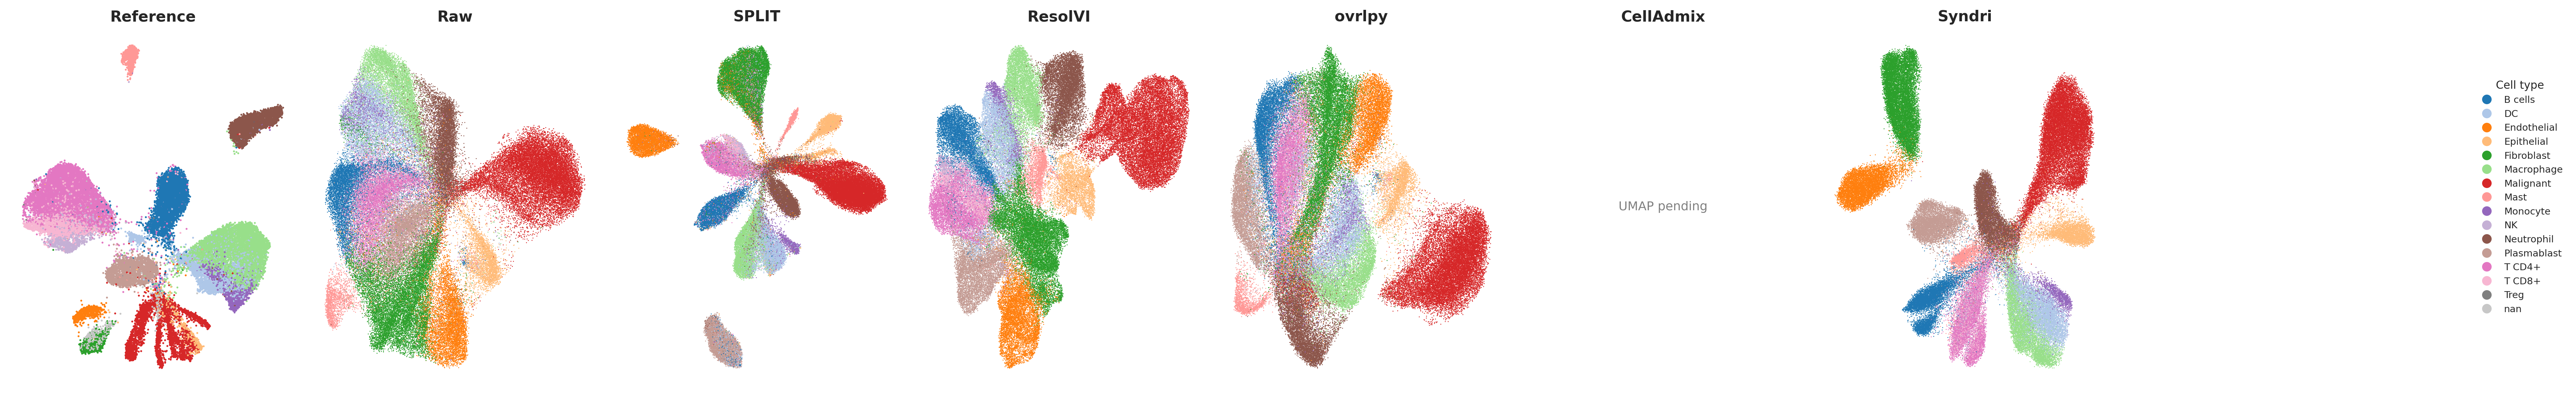

Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_nsclc_cosmx_Lung5_Rep1_qc10counts5genes_target0.pdf
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_nsclc_cosmx_Lung5_Rep1_qc10counts5genes_target0.png


In [ ]:

plot_order = PLOT_PANELS
missing_panels = [title for title in plot_order if title != 'CellAdmix' and title not in umap_adatas]
if missing_panels:
    raise KeyError(f'Missing UMAP panels: {missing_panels}')
plot_items = [(title, umap_adatas.get(title)) for title in plot_order]

categories = sorted({
    value
    for _, current in plot_items if current is not None
    for value in current.obs['cell_type_plot'].dropna().astype(str).unique()
})
colors = sns.color_palette('tab20', n_colors=len(categories))
# palette = dict(zip(categories, map(to_hex, colors)))
for _, current in plot_items:
    if current is not None:
        current.obs['cell_type_plot'] = pd.Categorical(current.obs['cell_type_plot'], categories=categories)

fig, axes = plt.subplots(1, len(plot_items), figsize=(max(4, 3.6 * len(plot_items)), 4.1),
                         dpi=300, squeeze=False)
axes = axes.ravel()
point_sizes = {'scRNA-seq reference': 2, 'Raw spatial': 0.5,
               'SPLIT-purified': 0.5, 'ResolVI-corrected': 0.5,
               'ovrlpy 0.7-corrected': 0.5, 'Syndri-cleaned': 0.5}
panel_titles = {'scRNA-seq reference': 'Reference', 'Raw spatial': 'Raw',
                'SPLIT-purified': 'SPLIT', 'ResolVI-corrected': 'ResolVI',
                'ovrlpy 0.7-corrected': 'ovrlpy', 'CellAdmix': 'CellAdmix',
                'Syndri-cleaned': 'Syndri'}
for i, (ax, (title, current)) in enumerate(zip(axes, plot_items)):
    if current is None:
        ax.text(0.5, 0.5, 'UMAP pending', ha='center', va='center', transform=ax.transAxes, color='0.5', fontsize=9)
        ax.set_title(panel_titles[title], fontsize=11, fontweight='bold')
        ax.axis('off')
        continue
    # sc.pl.umap(
    #     current, color='cell_type_plot', palette=palette, title=title, ax=ax, show=False,
    #     frameon=False, legend_loc=None, size=POINT_SIZE, alpha=0.75, rasterized=True,
    # )
    sns.scatterplot(data=current.obs, x=current.obsm['X_umap'][:,0],y=current.obsm['X_umap'][:,1],hue='cell_type_plot',hue_order=cell_type_order,palette=palette_dict,s=point_sizes[title],legend=False,ax=ax,edgecolor='none')
    ax.set_title(panel_titles[title], fontsize=11, fontweight='bold')
    ax.axis('off')

# Small UMAP coordinate arrows on the first panel only.
axis_ax = axes[0]
origin = (0.00, 0.00)
# axis_ax.annotate('', xy=(0.25, origin[1]), xytext=origin, xycoords='axes fraction', arrowprops=dict(arrowstyle='-|>', color='black', lw=2, mutation_scale=7))
# axis_ax.annotate('', xy=(origin[0], 0.25), xytext=origin, xycoords='axes fraction', arrowprops=dict(arrowstyle='-|>', color='black', lw=2, mutation_scale=7))
# axis_ax.text(0.125, -0.035, 'UMAP1', transform=axis_ax.transAxes, ha='center', va='top', fontsize=12)
# axis_ax.text(-0.035, 0.125, 'UMAP2', transform=axis_ax.transAxes, ha='right', va='center', rotation=90, fontsize=12)

handles = [Line2D([0], [0], marker='o', linestyle='', markerfacecolor=palette_dict[c], markeredgecolor='none', markersize=7, label=c) for c in cell_type_order]
fig.legend(handles=handles, labels=cell_type_order, title='Cell type', loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, ncol=1, fontsize=7, title_fontsize=8)
fig.tight_layout(rect=(0, 0, 0.86, 1), w_pad=1.2)
fig.savefig(OUTPUT_STEM.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(OUTPUT_STEM.with_suffix('.png'), dpi=400, bbox_inches='tight')
plt.show()
print(f'Saved {OUTPUT_STEM.with_suffix(".pdf")}')
print(f'Saved {OUTPUT_STEM.with_suffix(".png")}')

normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:01)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:32)
computing UMAP
    finished (0:00:56)


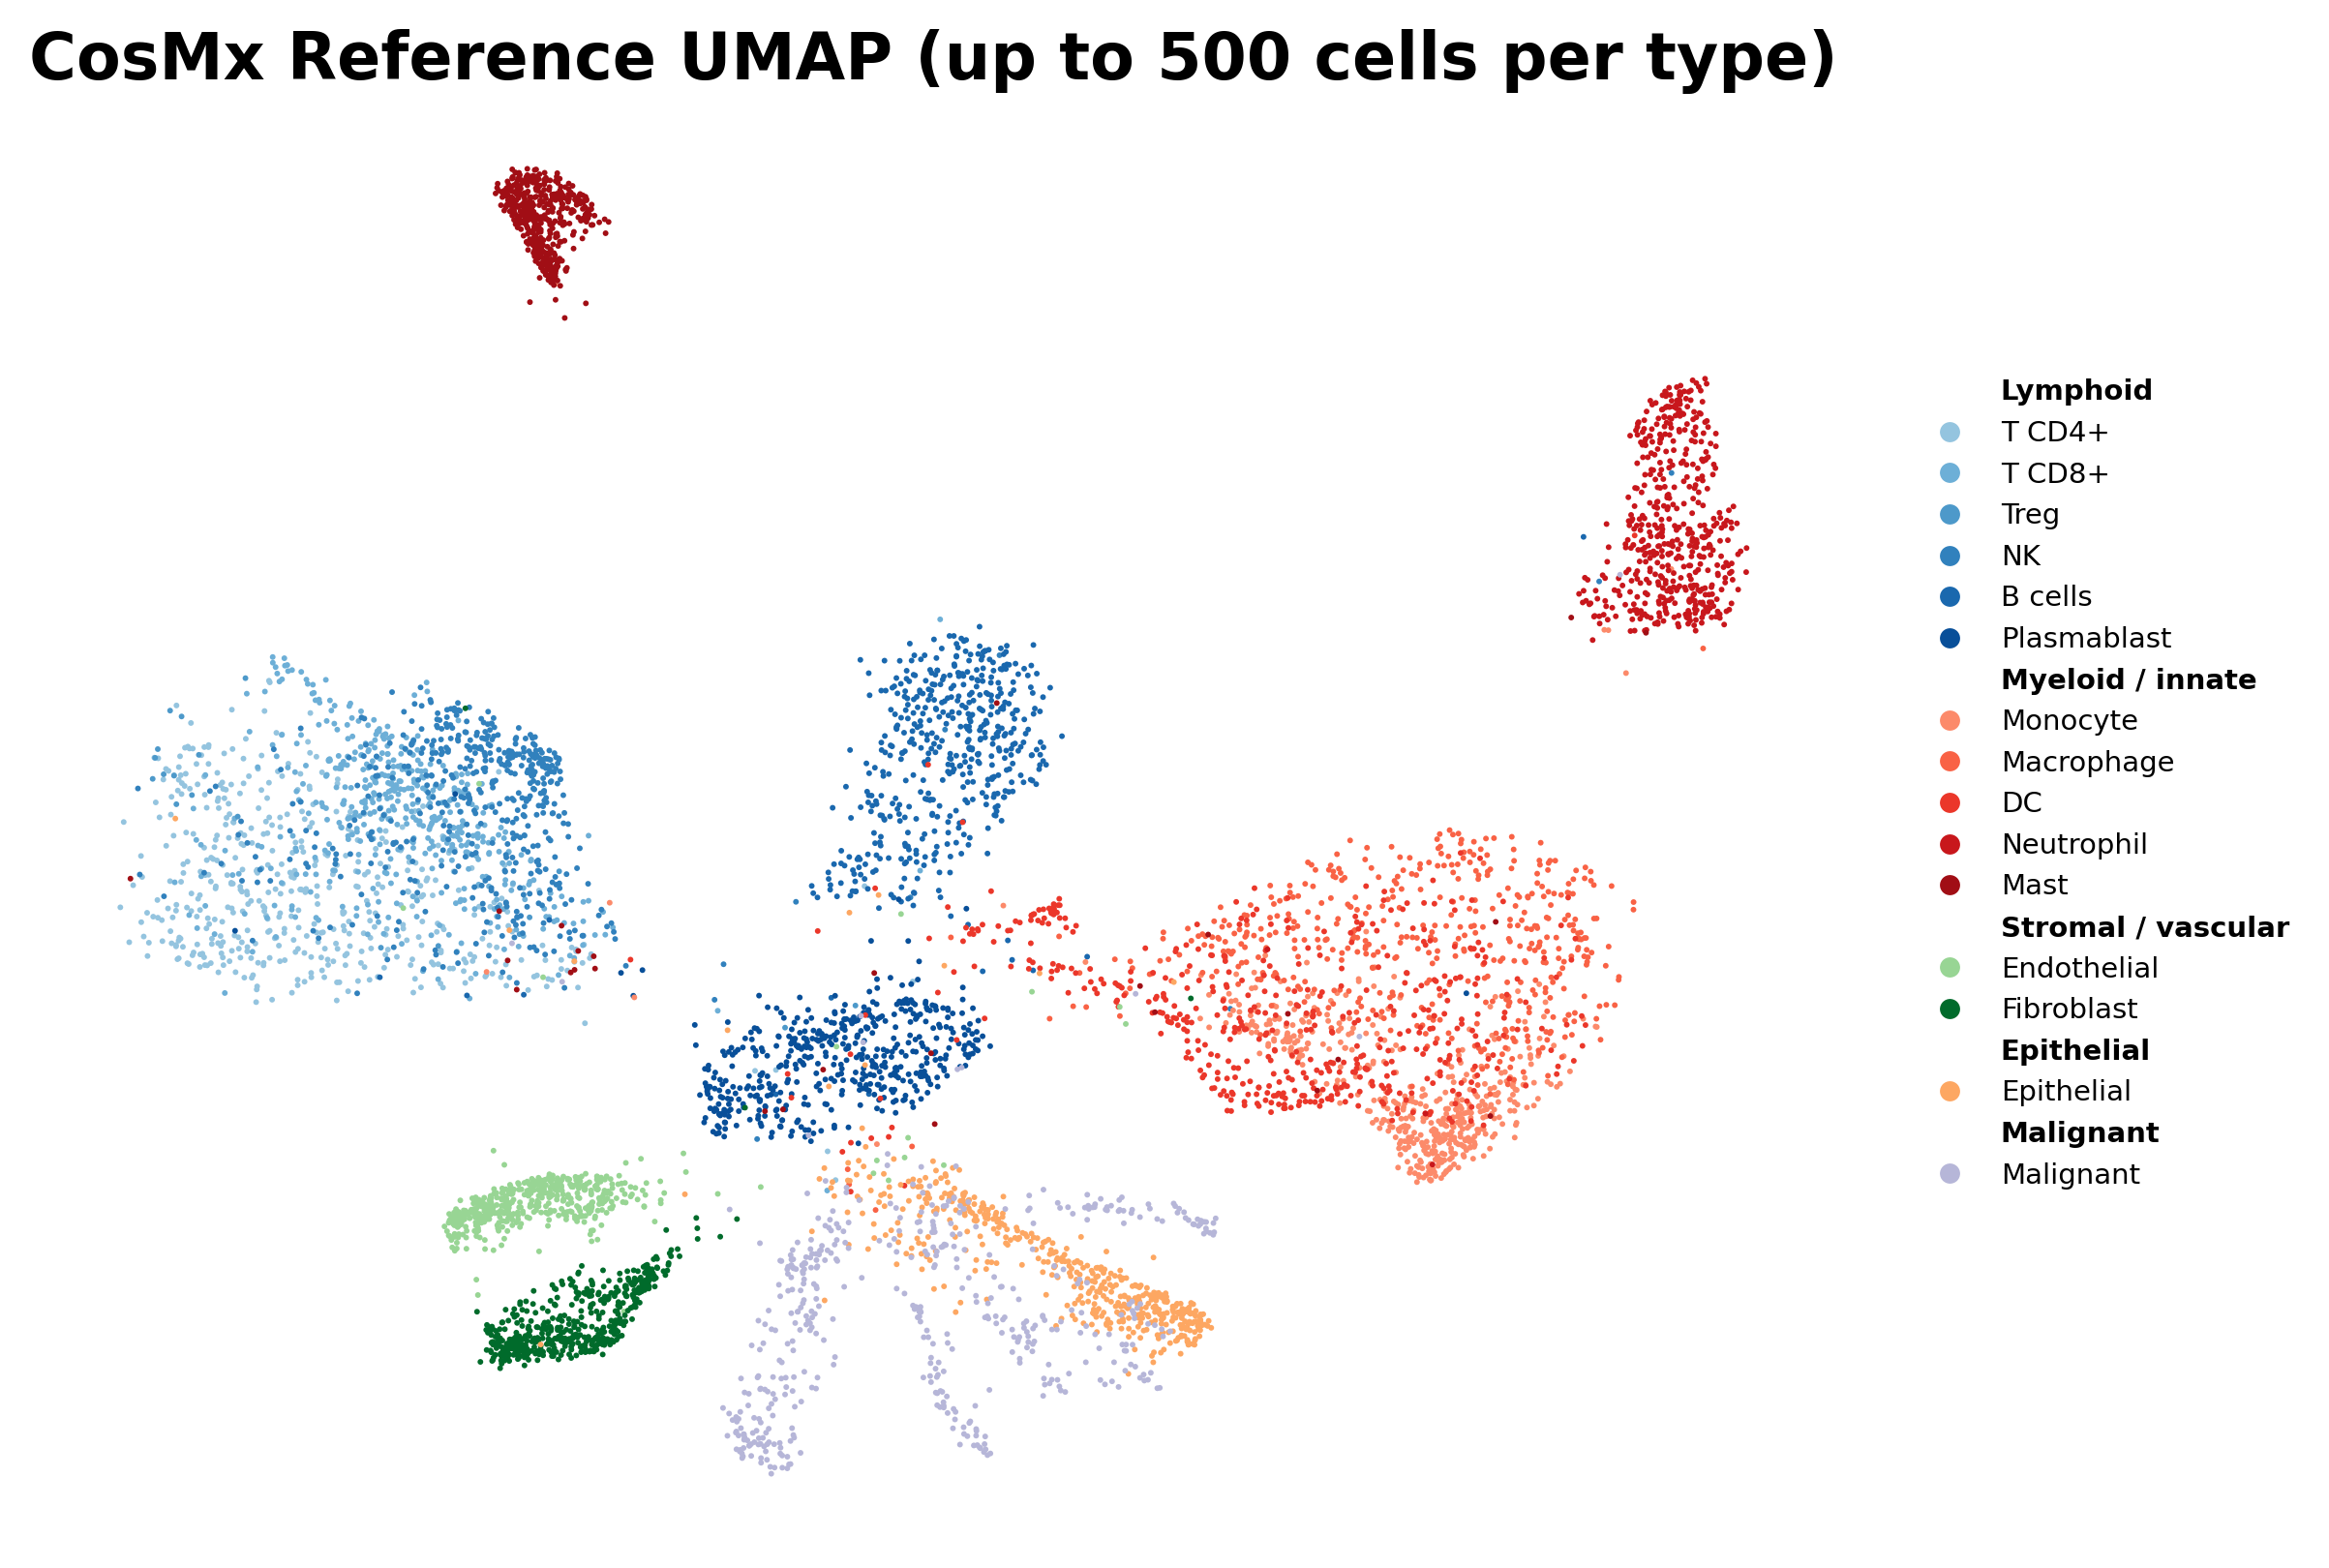

Reference QC retained: 40,296/40,362
Displayed cells: 7,019
Saved: /home/jwinchel/Syndri/figures/outputs/Figure2_CosMx_Reference_UMAP_subsampled_N500_per_type.pdf
Saved: /home/jwinchel/Syndri/figures/outputs/Figure2_CosMx_Reference_UMAP_subsampled_N500_per_type.png


In [1]:
# Standalone subsampled CosMx Reference UMAP.
# Edit N_PER_TYPE to control the maximum number of displayed cells per cell type.
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import scanpy as sc
import scipy.sparse as sp

REFERENCE_UMAP_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/interim/single-cell/sc_integrated.h5ad')
REFERENCE_UMAP_LABEL = 'cell_type_harmonized'
N_PER_TYPE = 500
SUBSAMPLE_RANDOM_STATE = 42
REFERENCE_UMAP_MIN_COUNTS = 10
REFERENCE_UMAP_MIN_GENES = 5
REFERENCE_UMAP_N_PCS = 50
REFERENCE_UMAP_N_NEIGHBORS = 15
REFERENCE_UMAP_MIN_DIST = 0.4
REFERENCE_UMAP_OUTPUT_DIR = Path('/home/jwinchel/Syndri/figures/outputs')
REFERENCE_UMAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sc.settings.verbosity = 2

# Exact colors from CosMxSliceMorphology.ipynb's exported cell-type color table.
CELL_TYPE_FAMILIES = [
    ('Lymphoid', ['T CD4+', 'T CD8+', 'Treg', 'NK', 'B cells', 'Plasmablast']),
    ('Myeloid / innate', ['Monocyte', 'Macrophage', 'DC', 'Neutrophil', 'Mast']),
    ('Stromal / vascular', ['Endothelial', 'Fibroblast']),
    ('Epithelial', ['Epithelial']),
    ('Malignant', ['Malignant']),
]
CELL_TYPE_PALETTE = {
    'T CD4+': '#94c4df', 'T CD8+': '#6dafd7', 'Treg': '#4d99ca',
    'NK': '#3181bd', 'B cells': '#1a68ae', 'Plasmablast': '#084f99',
    'Monocyte': '#fc8a6a', 'Macrophage': '#f96245', 'DC': '#eb372a',
    'Neutrophil': '#c8171c', 'Mast': '#a10e15',
    'Endothelial': '#98d594', 'Fibroblast': '#006b2b',
    'Epithelial': '#fda762', 'Malignant': '#b6b6d8',
}
CELL_TYPE_ORDER = [cell_type for _, labels in CELL_TYPE_FAMILIES for cell_type in labels]

if N_PER_TYPE < 1:
    raise ValueError('N_PER_TYPE must be a positive integer')
if not REFERENCE_UMAP_PATH.is_file():
    raise FileNotFoundError(REFERENCE_UMAP_PATH)
reference_subsample_source = ad.read_h5ad(REFERENCE_UMAP_PATH)
if REFERENCE_UMAP_LABEL not in reference_subsample_source.obs:
    raise KeyError(f'Missing reference label column: {REFERENCE_UMAP_LABEL}')

# Recreate the full-reference embedding using Figure 2's QC and UMAP settings,
# then sample plotted cells so the subsampling itself does not change the geometry.
reference_subsample_counts = reference_subsample_source.X
if sp.issparse(reference_subsample_counts):
    reference_subsample_counts = reference_subsample_counts.tocsr().astype(np.float32)
else:
    reference_subsample_counts = sp.csr_matrix(np.asarray(reference_subsample_counts, dtype=np.float32))
reference_subsample_total = np.asarray(reference_subsample_counts.sum(axis=1)).ravel()
reference_subsample_detected = np.asarray((reference_subsample_counts > 0).sum(axis=1)).ravel()
reference_subsample_qc = (
    (reference_subsample_total >= REFERENCE_UMAP_MIN_COUNTS)
    & (reference_subsample_detected >= REFERENCE_UMAP_MIN_GENES)
)
if reference_subsample_qc.sum() < 3:
    raise ValueError('Too few reference cells pass count and gene QC')
reference_subsample_adata = ad.AnnData(
    X=reference_subsample_counts[reference_subsample_qc].copy(),
    obs=reference_subsample_source.obs.loc[reference_subsample_qc].copy(),
    var=reference_subsample_source.var.copy(),
)
sc.pp.normalize_total(reference_subsample_adata, target_sum=10_000)
sc.pp.log1p(reference_subsample_adata)
reference_subsample_n_comps = min(
    REFERENCE_UMAP_N_PCS,
    reference_subsample_adata.n_obs - 1,
    reference_subsample_adata.n_vars - 1,
)
if reference_subsample_n_comps < 2:
    raise ValueError('Insufficient observations or genes for PCA')
sc.pp.pca(reference_subsample_adata, n_comps=reference_subsample_n_comps,
          random_state=SUBSAMPLE_RANDOM_STATE)
sc.pp.neighbors(
    reference_subsample_adata,
    n_neighbors=min(REFERENCE_UMAP_N_NEIGHBORS, reference_subsample_adata.n_obs - 1),
    n_pcs=reference_subsample_n_comps,
    random_state=SUBSAMPLE_RANDOM_STATE,
)
sc.tl.umap(reference_subsample_adata, min_dist=REFERENCE_UMAP_MIN_DIST,
           random_state=SUBSAMPLE_RANDOM_STATE)

reference_subsample_labels = (
    reference_subsample_adata.obs[REFERENCE_UMAP_LABEL].astype('string').str.strip()
)
valid_reference_labels = (
    reference_subsample_labels.notna()
    & ~reference_subsample_labels.str.lower().isin(['', 'nan', 'none', 'unassigned', '<na>'])
)
observed_reference_types = set(reference_subsample_labels.loc[valid_reference_labels].astype(str).unique())
unknown_reference_types = observed_reference_types - set(CELL_TYPE_PALETTE)
if unknown_reference_types:
    raise ValueError(f'Cell types missing from the morphology palette: {sorted(unknown_reference_types)}')
reference_subsample_labels = reference_subsample_labels.fillna('').astype(str).to_numpy()
reference_subsample_coordinates = reference_subsample_adata.obsm['X_umap']
reference_subsample_rng = np.random.default_rng(SUBSAMPLE_RANDOM_STATE)
reference_subsample_indices = {}
for cell_type in CELL_TYPE_ORDER:
    candidates = np.flatnonzero(
        valid_reference_labels.to_numpy()
        & (reference_subsample_labels == cell_type)
    )
    n_selected = min(N_PER_TYPE, len(candidates))
    if n_selected:
        reference_subsample_indices[cell_type] = np.sort(
            reference_subsample_rng.choice(candidates, size=n_selected, replace=False)
        )

fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=300)
for cell_type in CELL_TYPE_ORDER:
    indices = reference_subsample_indices.get(cell_type, np.array([], dtype=int))
    if len(indices):
        ax.scatter(
            reference_subsample_coordinates[indices, 0],
            reference_subsample_coordinates[indices, 1],
            s=2, color=CELL_TYPE_PALETTE[cell_type], edgecolor='none', rasterized=True,
        )
ax.set_title(f'CosMx Reference UMAP (up to {N_PER_TYPE:,} cells per type)',
             fontsize=16, fontweight='bold')
ax.axis('off')
legend_handles = []
family_header_indices = []
for family, cell_types in CELL_TYPE_FAMILIES:
    present_types = [cell_type for cell_type in cell_types if cell_type in reference_subsample_indices]
    if not present_types:
        continue
    family_header_indices.append(len(legend_handles))
    legend_handles.append(Line2D([], [], linestyle='', label=family))
    legend_handles.extend(
        Line2D([0], [0], marker='o', linestyle='', markerfacecolor=CELL_TYPE_PALETTE[cell_type],
               markeredgecolor='none', markersize=5, label=cell_type)
        for cell_type in present_types
    )
fig.legend(handles=legend_handles, loc='center left', bbox_to_anchor=(.77, .5),
           frameon=False, fontsize=7)
legend = fig.legends[0]
for index in family_header_indices:
    legend.get_texts()[index].set_fontweight('bold')
fig.tight_layout(rect=(0, 0, .76, 1))
reference_subsample_stem = REFERENCE_UMAP_OUTPUT_DIR / f'Figure2_CosMx_Reference_UMAP_subsampled_N{N_PER_TYPE}_per_type'
fig.savefig(reference_subsample_stem.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(reference_subsample_stem.with_suffix('.png'), dpi=400, bbox_inches='tight')
plt.show()
print(f'Reference QC retained: {reference_subsample_qc.sum():,}/{reference_subsample_source.n_obs:,}')
print(f'Displayed cells: {sum(len(indices) for indices in reference_subsample_indices.values()):,}')
print('Saved:', reference_subsample_stem.with_suffix('.pdf'))
print('Saved:', reference_subsample_stem.with_suffix('.png'))
